**Import Library**

In [ ]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.base import clone

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

**Load Dataset**

In [ ]:
file_path = "/content/Smartphone_Usage_And_Addiction_Analysis_7500_Rows.csv"
df = pd.read_csv(file_path)

In [ ]:
# Menampilkan ukuran data
print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (7500, 16)


,transaction_id,user_id,age,gender,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,stress_level,academic_work_impact,addiction_level,addicted_label
0,TXN00001,U00001,21,Male,3.23,2.01,0.89,4.55,7.55,248,154,3.95,Medium,Yes,NaN,0
1,TXN00002,U00002,24,Other,5.09,3.81,2.24,4.44,7.66,127,71,6.71,Medium,Yes,NaN,0
2,TXN00003,U00003,31,Other,6.06,1.36,3.83,2.35,4.92,44,106,8.68,High,No,Mild,0
3,TXN00004,U00004,32,Other,7.83,5.85,1.51,3.54,8.23,178,107,9.77,High,Yes,Moderate,1
4,TXN00005,U00005,25,Male,9.96,5.92,3.42,5.27,6.21,136,177,12.55,Low,No,Severe,1


**Pemeriksaan Awal Dataset**

In [ ]:
# Info dataset
print("Info dataset:")
df.info()

Info dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   transaction_id           7500 non-null   object 
 1   user_id                  7500 non-null   object 
 2   age                      7500 non-null   int64  
 3   gender                   7500 non-null   object 
 4   daily_screen_time_hours  7500 non-null   float64
 5   social_media_hours       7500 non-null   float64
 6   gaming_hours             7500 non-null   float64
 7   work_study_hours         7500 non-null   float64
 8   sleep_hours              7500 non-null   float64
 9   notifications_per_day    7500 non-null   int64  
 10  app_opens_per_day        7500 non-null   int64  
 11  weekend_screen_time      7500 non-null   float64
 12  stress_level             7500 non-null   object 
 13  academic_work_impact     7500 non-null   object 
 14  addiction_

In [ ]:
# Missing values
df.isna().sum().sort_values(ascending=False)

,0
addiction_level,819
transaction_id,0
age,0
user_id,0
daily_screen_time_hours,0
social_media_hours,0
gaming_hours,0
gender,0
work_study_hours,0
sleep_hours,0


In [ ]:
# Distribusi target
print("Distribusi target (addicted_label):")
display(df["addicted_label"].value_counts().to_frame("count"))

Distribusi target (addicted_label):


,count
addicted_label,
1,5308
0,2192


In [ ]:
# Persentase target
print("Persentase target:")
display(df["addicted_label"].value_counts(normalize=True).mul(100).round(2).to_frame("percentage"))


Persentase target:


,percentage
addicted_label,
1,70.77
0,29.23


In [ ]:
# Statistik deskriptif fitur numerik
print("Statistik deskriptif fitur numerik:")
display(df.describe().T)

Statistik deskriptif fitur numerik:


,count,mean,std,min,25%,50%,75%,max
age,7500.0,26.568800,5.197108,18.00,22.00,27.000,31.00,35.00
daily_screen_time_hours,7500.0,7.499912,2.609188,3.00,5.22,7.525,9.81,12.00
social_media_hours,7500.0,3.273484,1.585342,0.50,1.91,3.270,4.63,6.00
gaming_hours,7500.0,2.014183,1.146039,0.00,1.02,2.040,2.99,4.00
work_study_hours,7500.0,3.242420,1.600765,0.50,1.85,3.230,4.64,6.00
sleep_hours,7500.0,6.737561,1.283605,4.50,5.63,6.720,7.84,9.00
notifications_per_day,7500.0,134.257333,66.586883,20.00,76.00,134.000,191.00,250.00
app_opens_per_day,7500.0,97.832400,48.423349,15.00,55.00,98.000,140.00,180.00
weekend_screen_time,7500.0,9.243827,2.718281,3.58,6.96,9.260,11.54,14.88
addicted_label,7500.0,0.707733,0.454835,0.00,0.00,1.000,1.00,1.00


**Visualisasi Awal Dataset**

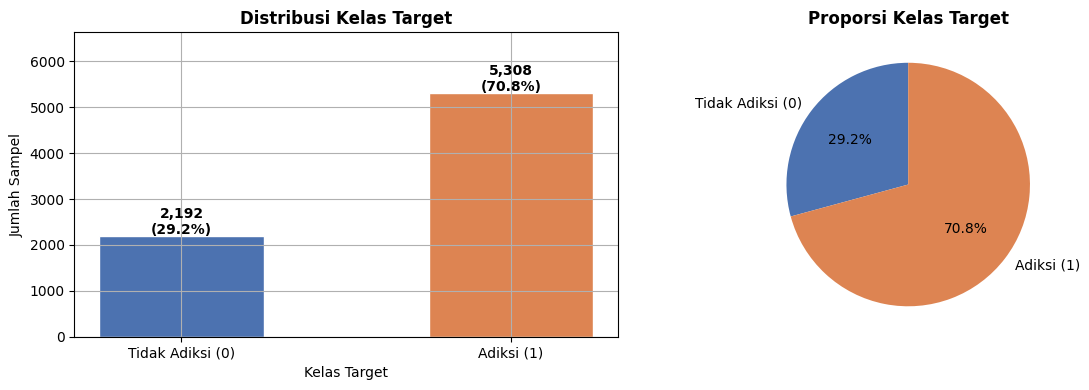

In [ ]:
# Visualisasi Distribusi Target
tc = df["addicted_label"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(["Tidak Adiksi (0)", "Adiksi (1)"], tc.values,
            color=["#4C72B0", "#DD8452"], edgecolor="white", width=0.5)
for i, (v, p) in enumerate(zip(tc.values, (tc/len(df)*100).values)):
    axes[0].text(i, v+50, f"{v:,}\n({p:.1f}%)", ha="center", fontweight="bold")

axes[0].set_title("Distribusi Kelas Target", fontweight="bold")
axes[0].set_xlabel("Kelas Target")
axes[0].set_ylabel("Jumlah Sampel")
axes[0].set_ylim(0, max(tc.values)*1.25)

axes[1].pie(tc.values, labels=["Tidak Adiksi (0)", "Adiksi (1)"],
            colors=["#4C72B0","#DD8452"], autopct="%1.1f%%", startangle=90)
axes[1].set_title("Proporsi Kelas Target", fontweight="bold")

plt.tight_layout()
plt.savefig("figures/target_distribution.png", dpi=300)
plt.show()

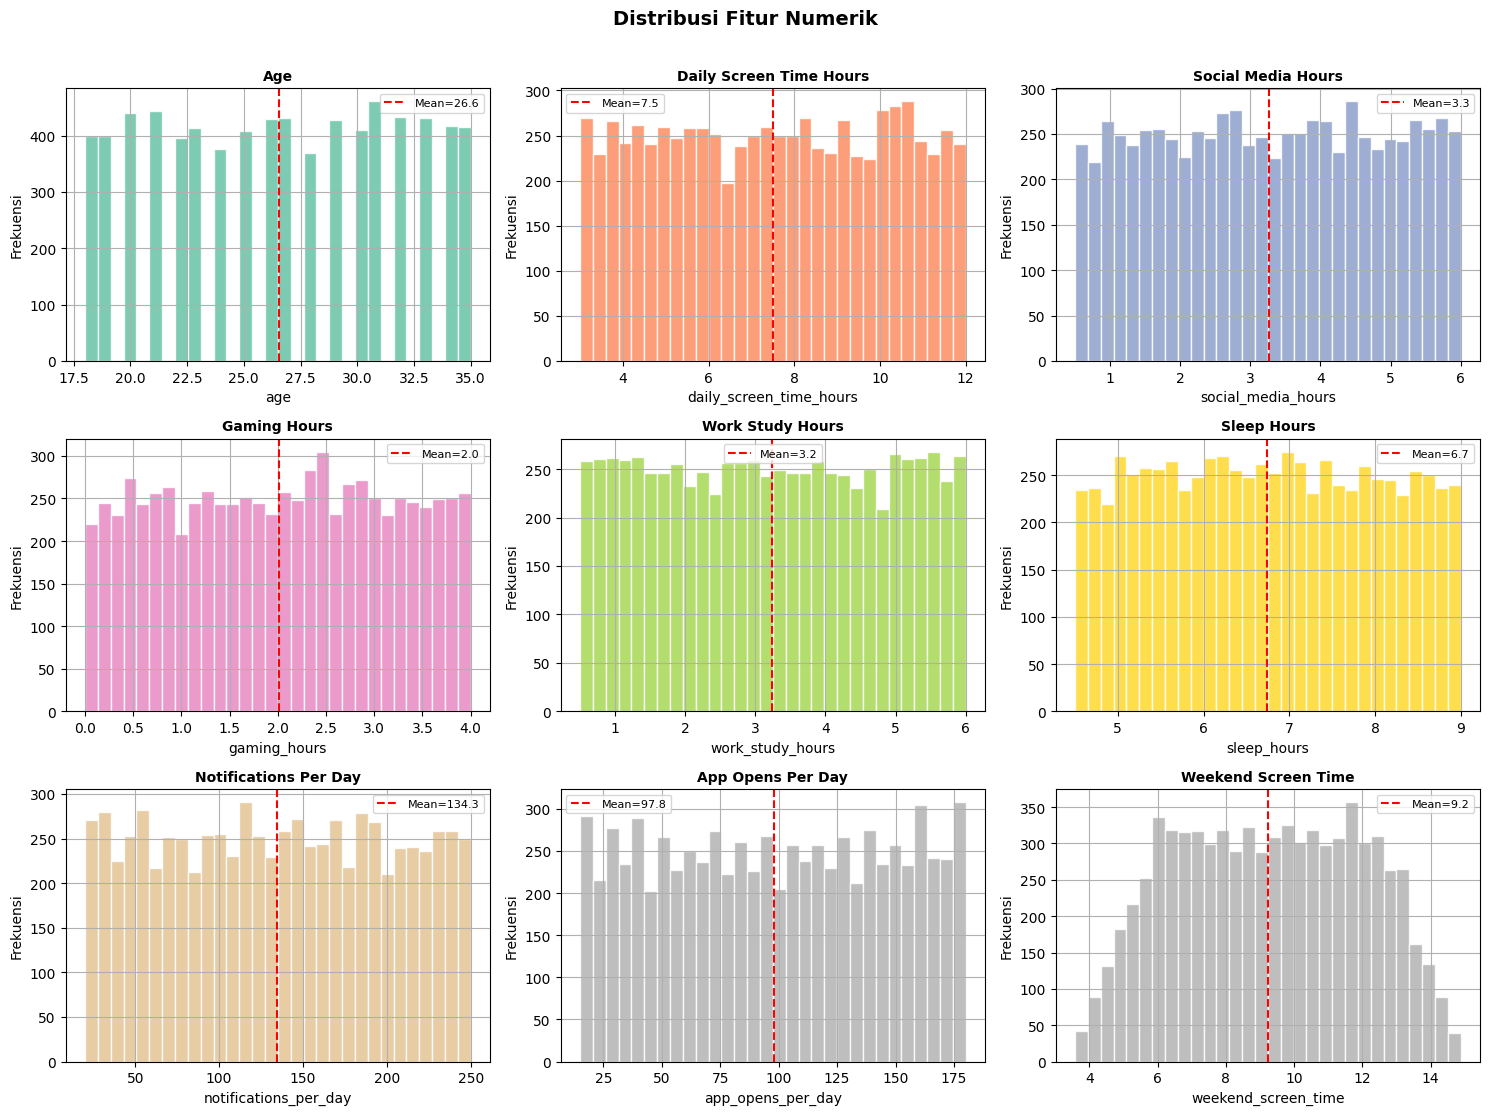

In [ ]:
# Distribusi Fitur Numerik
num_preview = [
    "age",
    "daily_screen_time_hours",
    "social_media_hours",
    "gaming_hours",
    "work_study_hours",
    "sleep_hours",
    "notifications_per_day",
    "app_opens_per_day",
    "weekend_screen_time"]

colors = plt.cm.Set2(np.linspace(0,1,len(num_preview)))
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(num_preview):
    axes[i].hist(df[col], bins=30, color=colors[i], edgecolor="white", alpha=0.85)
    axes[i].axvline(df[col].mean(), color="red", linestyle="--", lw=1.5,
                    label=f"Mean={df[col].mean():.1f}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frekuensi")
    axes[i].set_title(col.replace("_"," ").title(), fontweight="bold", fontsize=10)
    axes[i].legend(fontsize=8)

plt.suptitle("Distribusi Fitur Numerik", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("figures/numeric_features.png", dpi=300)
plt.show()

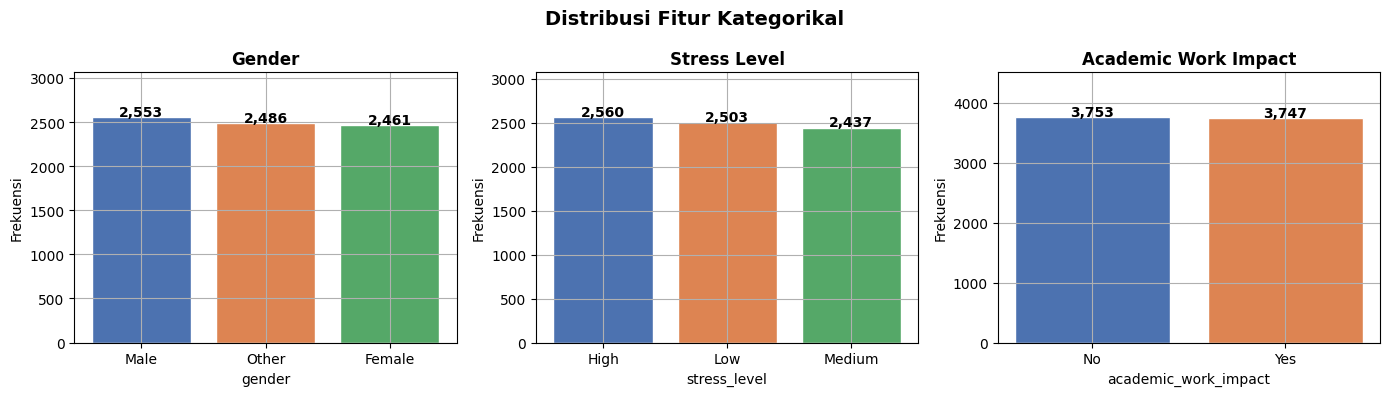

In [ ]:
# Distribusi Fitur Kategorikal
cat_preview = [
    "gender",
    "stress_level",
    "academic_work_impact"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
pal = ["#4C72B0","#DD8452","#55A868","#C44E52"]

for i, col in enumerate(cat_preview):
    counts = df[col].value_counts()
    axes[i].bar(counts.index, counts.values, color=pal[:len(counts)], edgecolor="white")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frekuensi")
    for j,v in enumerate(counts.values):
        axes[i].text(j, v+20, f"{v:,}", ha="center", fontweight="bold")
    axes[i].set_title(col.replace("_"," ").title(), fontweight="bold")
    axes[i].set_ylim(0, max(counts.values)*1.2)

plt.suptitle("Distribusi Fitur Kategorikal", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/categorical_features.png", dpi=300)
plt.show()

**Penentuan Variabel Input dan Target**

In [ ]:
target_col = "addicted_label"
drop_cols = ["transaction_id", "user_id", "addiction_level", target_col]

# Variabel Input
X = df.drop(columns=drop_cols, errors="ignore")

# Variabel Target
y = df[target_col].astype(int)

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

print("\nFitur input yang digunakan:")
print(X.columns.tolist())

print("\nJumlah fitur  :", X.shape[1])
print("Jumlah sampel :", X.shape[0])

print(f"Distribusi y  : {y.value_counts().to_dict()}")

Ukuran X: (7500, 12)
Ukuran y: (7500,)

Fitur input yang digunakan:
['age', 'gender', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours', 'work_study_hours', 'sleep_hours', 'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time', 'stress_level', 'academic_work_impact']

Jumlah fitur  : 12
Jumlah sampel : 7500
Distribusi y  : {1: 5308, 0: 2192}


**Memisahkan Kolom Numerik dan Kategorikal**

In [ ]:
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()

# Kolom Numerik
print(f"Kolom numerik ({len(numeric_cols)})     :")
print(numeric_cols)

# Kolom Kategorikal
print(f"\nKolom kategorikal ({len(categorical_cols)}) :")
print(categorical_cols)

Kolom numerik (9)     :
['age', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours', 'work_study_hours', 'sleep_hours', 'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time']

Kolom kategorikal (3) :
['gender', 'stress_level', 'academic_work_impact']


**Prapemrosesan Data**

In [ ]:
# Transformasi untuk numerik
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler())
])

# Transformasi untuk kategorikal
try:
    ohe = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(drop="first", handle_unknown="ignore", sparse=False)

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot",  ohe)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ],
    remainder="drop"
)

**Model**

In [ ]:
knn_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean'
))
])

dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        criterion="entropy",
        max_depth=6,
        random_state=42
    ))
])

ann_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='logistic',
    solver='adam',
    max_iter=500,
    random_state=42
))
])

models = {
    "KNN": knn_model,
    "Decision Tree": dt_model,
    "ANN": ann_model
}

MODEL_COLORS = {"KNN": "#4C72B0", "Decision Tree": "#DD8452", "ANN": "#55A868"}

**Fungsi Evaluasi dan Visualisasi**

In [ ]:
# Conf Matrix
def plot_cm_single(cm, title, ax=None, cmap="Blues"):
    if ax is None:
        fig, ax = plt.subplots(figsize=(4, 3))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(values_format="d", cmap=cmap, ax=ax, colorbar=False)
    ax.set_title(title, fontweight="bold", fontsize=10)
    ax.set_xlabel("Prediksi", fontsize=9)
    ax.set_ylabel("Aktual", fontsize=9)

def plot_cm_grid(cms, model_name, cmap="Blues"):
    n = len(cms)
    fig, axes = plt.subplots(1, n, figsize=(n*4, 3.5))
    if n == 1: axes = [axes]
    for i, (cm, ax) in enumerate(zip(cms, axes)):
        plot_cm_single(cm, f"{model_name}\nFold {i+1}", ax=ax, cmap=cmap)
    fig.suptitle(f"Confusion Matrix per Fold — {model_name}", fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(f"figures/cm_fold_{model_name.replace(' ','_').lower()}.png", bbox_inches="tight")
    plt.show()

# Conf Matrix (Agregasi)
def aggregate_cm(cms):
    total = np.zeros((2, 2), dtype=int)
    for cm in cms:
      total += cm
    return total

# Tabel per Fold
def print_fold_table(df_rows, model_name):
    print(f"\n{'='*72}")
    print(f"  {model_name} — Tabel Hasil per Fold")
    print(f"{'='*72}")
    print(f"  {'Fold':>4}  {'Accuracy':>10}  {'Precision':>10}  {'Recall':>10}  {'F1-Score':>10}  {'Waktu(s)':>10}")
    print(f"  {'-'*60}")
    for _, r in df_rows.iterrows():
        print(f"  {int(r.fold):>4}  {r.accuracy:>10.4f}  {r.precision:>10.4f}  "
              f"{r.recall:>10.4f}  {r.f1_score:>10.4f}  {r.time_sec:>10.6f}")
    avgs = df_rows[["accuracy","precision","recall","f1_score","time_sec"]].mean()
    print(f"  {'-'*60}")
    print(f"  {'Mean':>4}  {avgs.accuracy:>10.4f}  {avgs.precision:>10.4f}  "
          f"{avgs.recall:>10.4f}  {avgs.f1_score:>10.4f}  {avgs.time_sec:>10.6f}")
    print(f"{'='*72}")
    return avgs

In [ ]:
# Stratified K-Fold
def evaluate_kfold(model, X, y, model_name, n_splits=5, random_state=42):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    rows = []
    cms = []

    print(f"\nVerifikasi distribusi kelas per fold ({model_name}):")
    for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
        prop_tr = y.iloc[train_idx].mean()*100
        prop_te = y.iloc[test_idx].mean()*100
        print(f"  Fold {fold}: Train adiksi={prop_tr:.1f}%  |  Test adiksi={prop_te:.1f}%")
    print()

    for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        fold_model = clone(model)

        start = time.perf_counter()
        fold_model.fit(X_train, y_train)
        y_pred = fold_model.predict(X_test)
        elapsed = time.perf_counter() - start

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
        rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
        f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
        cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

        rows.append({
            "model": model_name,
            "fold": fold,
            "accuracy": acc,
            "precision": prec,
            "recall": rec,
            "f1_score": f1,
            "time_sec": elapsed,
            "tn": cm[0, 0],
            "fp": cm[0, 1],
            "fn": cm[1, 0],
            "tp": cm[1, 1]
        })
        cms.append(cm)

        print(f"\n{model_name} - Fold {fold}")
        print(f"Accuracy  : {acc:.4f}")
        print(f"Precision : {prec:.4f}")
        print(f"Recall    : {rec:.4f}")
        print(f"F1-score  : {f1:.4f}")
        print(f"Time (s)  : {elapsed:.4f}")
        print("Classification report:")
        print(classification_report(y_test, y_pred, digits=4))

    return pd.DataFrame(rows), cms

# Split
def evaluate_split_repeated(model, X, y, model_name, test_size=0.2, n_repeats=5, base_random_state=42):
    rows = []
    cms = []

    for i in range(n_repeats):
        rs = base_random_state + i
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=rs, stratify=y
        )

        fold_model = clone(model)

        start = time.perf_counter()
        fold_model.fit(X_train, y_train)
        y_pred = fold_model.predict(X_test)
        elapsed = time.perf_counter() - start

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, average="weighted",zero_division=0)
        rec = recall_score(y_test, y_pred, average="weighted",zero_division=0)
        f1 = f1_score(y_test, y_pred, average="weighted",zero_division=0)
        cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

        rows.append({
            "model": model_name,
            "repeat": i + 1,
            "random_state": rs,
            "train_size": 1 - test_size,
            "test_size": test_size,
            "accuracy": acc,
            "precision": prec,
            "recall": rec,
            "f1_score": f1,
            "time_sec": elapsed,
            "tn": cm[0, 0],
            "fp": cm[0, 1],
            "fn": cm[1, 0],
            "tp": cm[1, 1]
        })
        cms.append(cm)

        print(f"\n{model_name} - Split {int((1-test_size)*100)}:{int(test_size*100)} | Repeat {i+1}")
        print(f"Accuracy  : {acc:.4f}")
        print(f"Precision : {prec:.4f}")
        print(f"Recall    : {rec:.4f}")
        print(f"F1-score  : {f1:.4f}")
        print(f"Time (s)  : {elapsed:.4f}")

    return pd.DataFrame(rows), cms

**Evaluasi K-Fold KNN**

In [ ]:
knn_kfold_df, knn_kfold_cms = evaluate_kfold(knn_model, X, y, "KNN", n_splits=5)


Verifikasi distribusi kelas per fold (KNN):
  Fold 1: Train adiksi=70.8%  |  Test adiksi=70.7%
  Fold 2: Train adiksi=70.8%  |  Test adiksi=70.7%
  Fold 3: Train adiksi=70.8%  |  Test adiksi=70.8%
  Fold 4: Train adiksi=70.8%  |  Test adiksi=70.8%
  Fold 5: Train adiksi=70.8%  |  Test adiksi=70.8%


KNN - Fold 1
Accuracy  : 0.8907
Precision : 0.8896
Recall    : 0.8907
F1-score  : 0.8900
Time (s)  : 0.2441
Classification report:
              precision    recall  f1-score   support

           0     0.8266    0.7927    0.8093       439
           1     0.9157    0.9312    0.9234      1061

    accuracy                         0.8907      1500
   macro avg     0.8711    0.8620    0.8663      1500
weighted avg     0.8896    0.8907    0.8900      1500


KNN - Fold 2
Accuracy  : 0.8993
Precision : 0.8984
Recall    : 0.8993
F1-score  : 0.8987
Time (s)  : 0.2209
Classification report:
              precision    recall  f1-score   support

           0     0.8412    0.8087    0.8246       439

In [ ]:
avgs_knn = print_fold_table(knn_kfold_df, "KNN")


  KNN — Tabel Hasil per Fold
  Fold    Accuracy   Precision      Recall    F1-Score    Waktu(s)
  ------------------------------------------------------------
     1      0.8907      0.8896      0.8907      0.8900    0.244088
     2      0.8993      0.8984      0.8993      0.8987    0.220935
     3      0.8747      0.8750      0.8747      0.8748    0.216411
     4      0.8927      0.8916      0.8927      0.8920    0.223352
     5      0.8860      0.8844      0.8860      0.8848    0.215040
  ------------------------------------------------------------
  Mean      0.8887      0.8878      0.8887      0.8881    0.223965


In [ ]:
# Tabel Waktu Pelatihan KNN
print("Waktu Pelatihan KNN")
print(f"  {'Fold':>4}  {'Waktu (detik)':>20}")
print("  " + "-"*28)
for _, r in knn_kfold_df.iterrows():
    print(f"  {int(r.fold):>4}  {r.time_sec:>20.6f}")
print("  " + "-"*28)
print(f"  {'Mean':>4}  {knn_kfold_df.time_sec.mean():>20.7f}")

Waktu Pelatihan KNN
  Fold         Waktu (detik)
  ----------------------------
     1              0.244088
     2              0.220935
     3              0.216411
     4              0.223352
     5              0.215040
  ----------------------------
  Mean             0.2239652


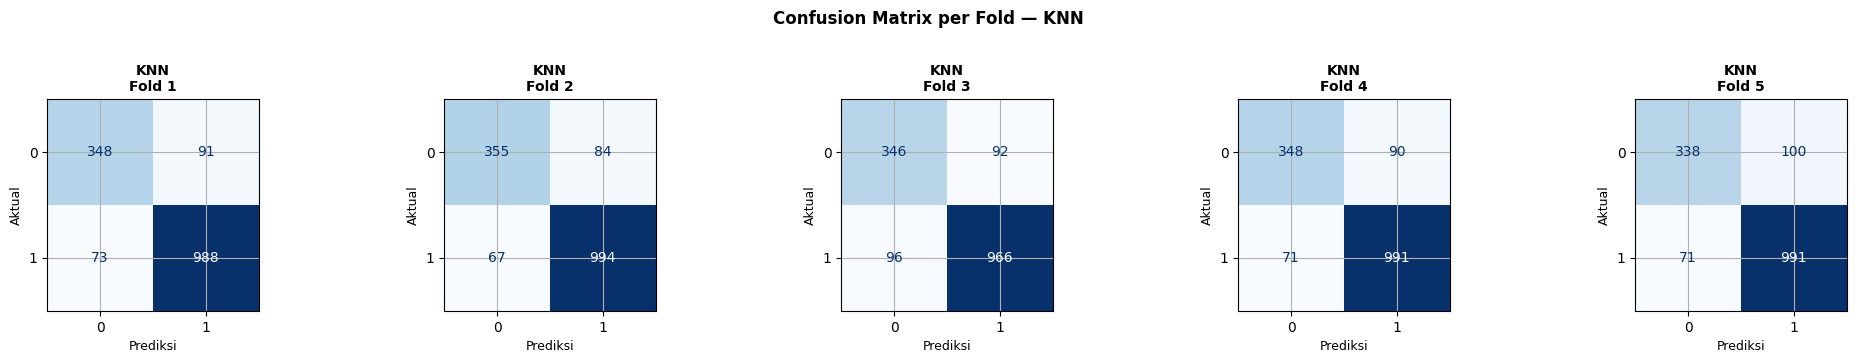

In [ ]:
# Confusion Matrix per Fold (KNN)
plot_cm_grid(knn_kfold_cms, "KNN", cmap="Blues")

**Evaluasi K-Fold Decision Tree**

In [ ]:
dt_kfold_df, dt_kfold_cms = evaluate_kfold(dt_model, X, y, "Decision Tree", n_splits=5)


Verifikasi distribusi kelas per fold (Decision Tree):
  Fold 1: Train adiksi=70.8%  |  Test adiksi=70.7%
  Fold 2: Train adiksi=70.8%  |  Test adiksi=70.7%
  Fold 3: Train adiksi=70.8%  |  Test adiksi=70.8%
  Fold 4: Train adiksi=70.8%  |  Test adiksi=70.8%
  Fold 5: Train adiksi=70.8%  |  Test adiksi=70.8%


Decision Tree - Fold 1
Accuracy  : 0.9333
Precision : 0.9404
Recall    : 0.9333
F1-score  : 0.9347
Time (s)  : 0.0497
Classification report:
              precision    recall  f1-score   support

           0     0.8330    0.9658    0.8945       439
           1     0.9849    0.9199    0.9513      1061

    accuracy                         0.9333      1500
   macro avg     0.9089    0.9429    0.9229      1500
weighted avg     0.9404    0.9333    0.9347      1500


Decision Tree - Fold 2
Accuracy  : 0.9413
Precision : 0.9410
Recall    : 0.9413
F1-score  : 0.9407
Time (s)  : 0.0488
Classification report:
              precision    recall  f1-score   support

           0     0.9312

In [ ]:
avgs_dt = print_fold_table(dt_kfold_df, "Decision Tree")


  Decision Tree — Tabel Hasil per Fold
  Fold    Accuracy   Precision      Recall    F1-Score    Waktu(s)
  ------------------------------------------------------------
     1      0.9333      0.9404      0.9333      0.9347    0.049678
     2      0.9413      0.9410      0.9413      0.9407    0.048830
     3      0.9320      0.9437      0.9320      0.9337    0.049822
     4      0.9380      0.9485      0.9380      0.9395    0.049445
     5      0.9333      0.9329      0.9333      0.9325    0.065582
  ------------------------------------------------------------
  Mean      0.9356      0.9413      0.9356      0.9362    0.052672


In [ ]:
# Tabel Waktu Pelatihan Decision Tree
print("Waktu Pelatihan Decision Tree")
print(f"  {'Fold':>4}  {'Waktu (detik)':>20}")
print("  " + "-"*28)
for _, r in dt_kfold_df.iterrows():
    print(f"  {int(r.fold):>4}  {r.time_sec:>20.6f}")
print("  " + "-"*28)
print(f"  {'Mean':>4}  {dt_kfold_df.time_sec.mean():>20.7f}")

Waktu Pelatihan Decision Tree
  Fold         Waktu (detik)
  ----------------------------
     1              0.049678
     2              0.048830
     3              0.049822
     4              0.049445
     5              0.065582
  ----------------------------
  Mean             0.0526717


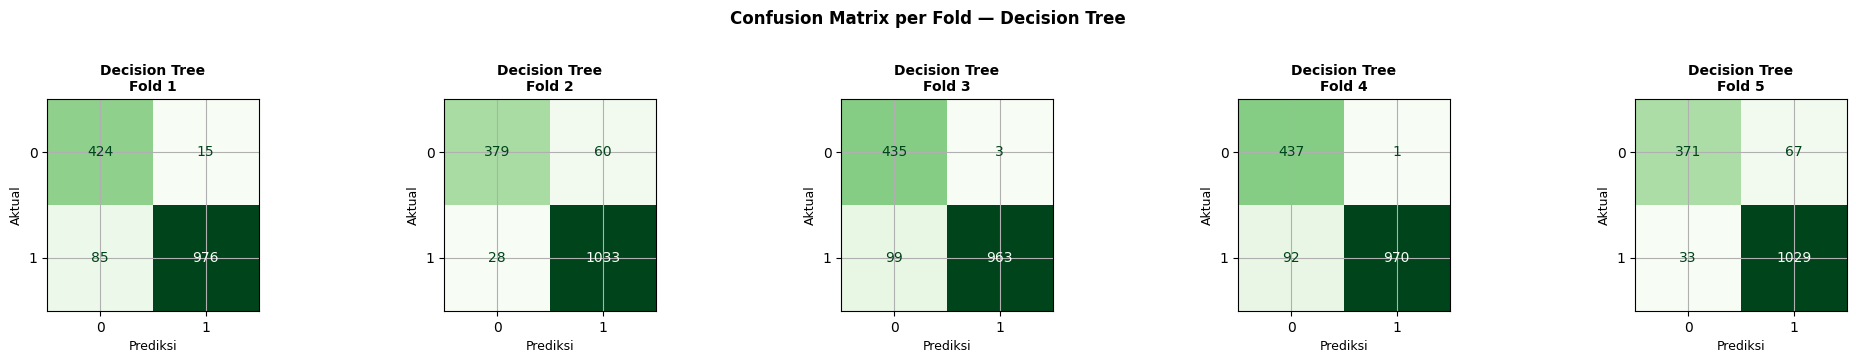

In [ ]:
# Confusion Matrix per Fold (Decision Tree)
plot_cm_grid(dt_kfold_cms, "Decision Tree", cmap="Greens")

**K-Fold ANN**

In [ ]:
ann_kfold_df, ann_kfold_cms = evaluate_kfold(ann_model, X, y, "ANN", n_splits=5)


Verifikasi distribusi kelas per fold (ANN):
  Fold 1: Train adiksi=70.8%  |  Test adiksi=70.7%
  Fold 2: Train adiksi=70.8%  |  Test adiksi=70.7%
  Fold 3: Train adiksi=70.8%  |  Test adiksi=70.8%
  Fold 4: Train adiksi=70.8%  |  Test adiksi=70.8%
  Fold 5: Train adiksi=70.8%  |  Test adiksi=70.8%


ANN - Fold 1
Accuracy  : 0.9300
Precision : 0.9298
Recall    : 0.9300
F1-score  : 0.9299
Time (s)  : 15.3587
Classification report:
              precision    recall  f1-score   support

           0     0.8848    0.8747    0.8797       439
           1     0.9484    0.9529    0.9506      1061

    accuracy                         0.9300      1500
   macro avg     0.9166    0.9138    0.9152      1500
weighted avg     0.9298    0.9300    0.9299      1500


ANN - Fold 2
Accuracy  : 0.9353
Precision : 0.9359
Recall    : 0.9353
F1-score  : 0.9356
Time (s)  : 16.0157
Classification report:
              precision    recall  f1-score   support

           0     0.8800    0.9021    0.8909       4

In [ ]:
avgs_ann = print_fold_table(ann_kfold_df, "ANN (MLP)")


  ANN (MLP) — Tabel Hasil per Fold
  Fold    Accuracy   Precision      Recall    F1-Score    Waktu(s)
  ------------------------------------------------------------
     1      0.9300      0.9298      0.9300      0.9299   15.358684
     2      0.9353      0.9359      0.9353      0.9356   16.015682
     3      0.9280      0.9295      0.9280      0.9285   17.262688
     4      0.9267      0.9272      0.9267      0.9269   15.189818
     5      0.9333      0.9343      0.9333      0.9337   15.378652
  ------------------------------------------------------------
  Mean      0.9307      0.9313      0.9307      0.9309   15.841105


In [ ]:
# Tabel Waktu Pelatihan ANN
print("Waktu Pelatihan ANN")
print(f"  {'Fold':>4}  {'Waktu (detik)':>20}")
print("  " + "-"*28)
for _, r in ann_kfold_df.iterrows():
    print(f"  {int(r.fold):>4}  {r.time_sec:>20.6f}")
print("  " + "-"*28)
print(f"  {'Mean':>4}  {ann_kfold_df.time_sec.mean():>20.7f}")

Waktu Pelatihan ANN
  Fold         Waktu (detik)
  ----------------------------
     1             15.358684
     2             16.015682
     3             17.262688
     4             15.189818
     5             15.378652
  ----------------------------
  Mean            15.8411047


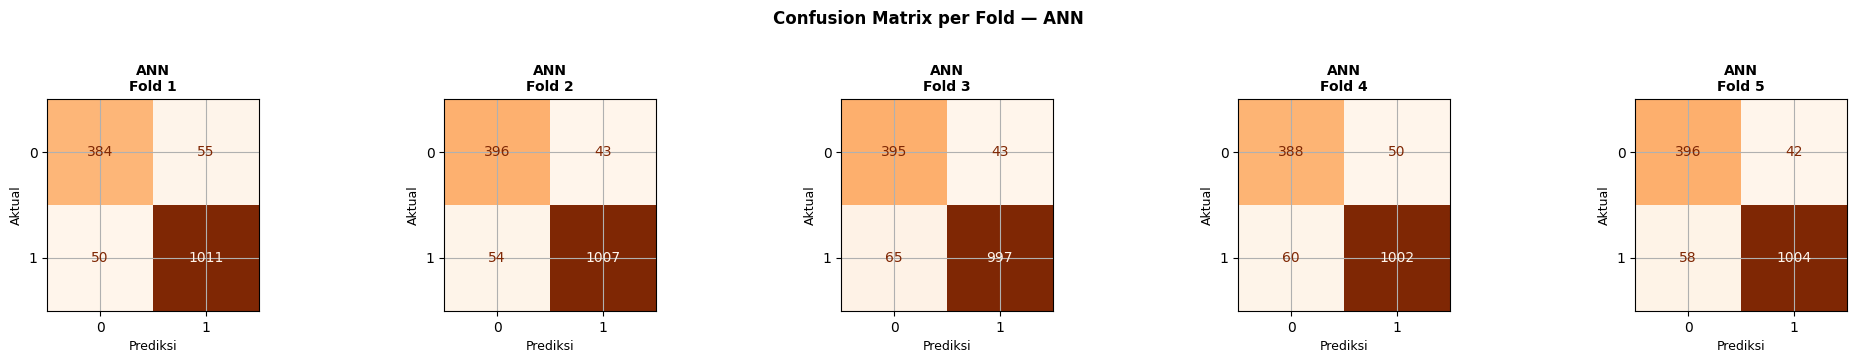

In [ ]:
# Confusion Matrix per Fold (ANN)
plot_cm_grid(ann_kfold_cms, "ANN", cmap="Oranges")

**Perbandingan Hasil K-Fold**

In [ ]:
# Tabel ringkasan
kfold_summary = pd.DataFrame({
    "KNN":           knn_kfold_df[["accuracy","precision","recall","f1_score","time_sec"]].mean(),
    "Decision Tree": dt_kfold_df[["accuracy","precision","recall","f1_score","time_sec"]].mean(),
    "ANN":           ann_kfold_df[["accuracy","precision","recall","f1_score","time_sec"]].mean(),
}).T

print("PERBANDINGAN RATA-RATA K-FOLD (KNN, Decision Tree, dan ANN)")
display(kfold_summary.round(4))

best = kfold_summary["accuracy"].idxmax()
fast = kfold_summary["time_sec"].idxmin()
print(f"\nAkurasi Terbaik  : {best} ({kfold_summary.loc[best,'accuracy']*100:.2f}%)")
print(f"Waktu Tercepat   : {fast} ({kfold_summary.loc[fast,'time_sec']:.6f}s)")

kfold_summary.to_csv("results/kfold_summary.csv")

PERBANDINGAN RATA-RATA K-FOLD (KNN, Decision Tree, dan ANN)


,accuracy,precision,recall,f1_score,time_sec
KNN,0.8887,0.8878,0.8887,0.8881,0.2240
Decision Tree,0.9356,0.9413,0.9356,0.9362,0.0527
ANN,0.9307,0.9313,0.9307,0.9309,15.8411



Akurasi Terbaik  : Decision Tree (93.56%)
Waktu Tercepat   : Decision Tree (0.052672s)


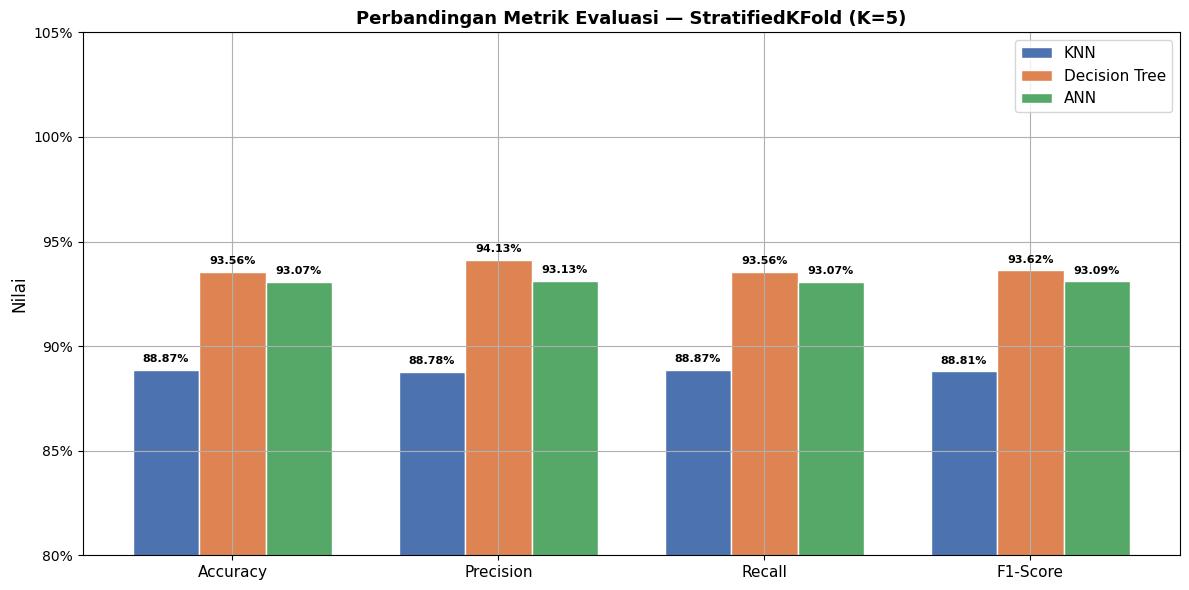

In [ ]:
# Bar Chart
metrics  = ["accuracy","precision","recall","f1_score"]
labels   = ["Accuracy","Precision","Recall","F1-Score"]
mn_list  = ["KNN","Decision Tree","ANN"]
colors_b = [MODEL_COLORS[m] for m in mn_list]
x = np.arange(len(metrics)); w = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
for i, (mn, col) in enumerate(zip(mn_list, colors_b)):
    vals = [kfold_summary.loc[mn, m] for m in metrics]
    bars = ax.bar(x + i*w, vals, w, label=mn, color=col, edgecolor="white")
    for bar in bars:
        ax.annotate(f"{bar.get_height()*100:.2f}%",
                    xy=(bar.get_x()+bar.get_width()/2, bar.get_height()),
                    xytext=(0,4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, fontweight="bold")

ax.set_xticks(x+w); ax.set_xticklabels(labels, fontsize=11)
ax.set_ylim(0.8, 1.05)
ax.set_ylabel("Nilai", fontsize=12)
ax.set_title("Perbandingan Metrik Evaluasi — StratifiedKFold (K=5)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_: f"{v:.0%}"))
plt.tight_layout()
plt.savefig("figures/kfold_metrics_comparison.png", bbox_inches="tight")
plt.show()

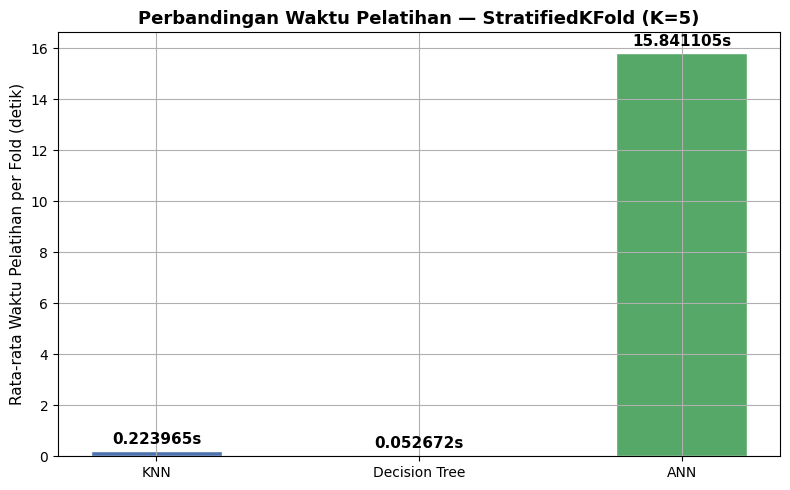

In [ ]:
# Bar Chart Waktu Pelatihan
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(mn_list, [kfold_summary.loc[m,"time_sec"] for m in mn_list],
              color=colors_b, edgecolor="white", width=0.5)

for bar in bars:
    ax.annotate(f"{bar.get_height():.6f}s",
                xy=(bar.get_x()+bar.get_width()/2, bar.get_height()),
                xytext=(0,5), textcoords="offset points",
                ha="center", fontweight="bold", fontsize=11)
ax.set_ylabel("Rata-rata Waktu Pelatihan per Fold (detik)", fontsize=11)
ax.set_title("Perbandingan Waktu Pelatihan — StratifiedKFold (K=5)",
             fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig("figures/kfold_training_time.png", bbox_inches="tight")
plt.show()

**Confusion Matrix Total K-Fold**

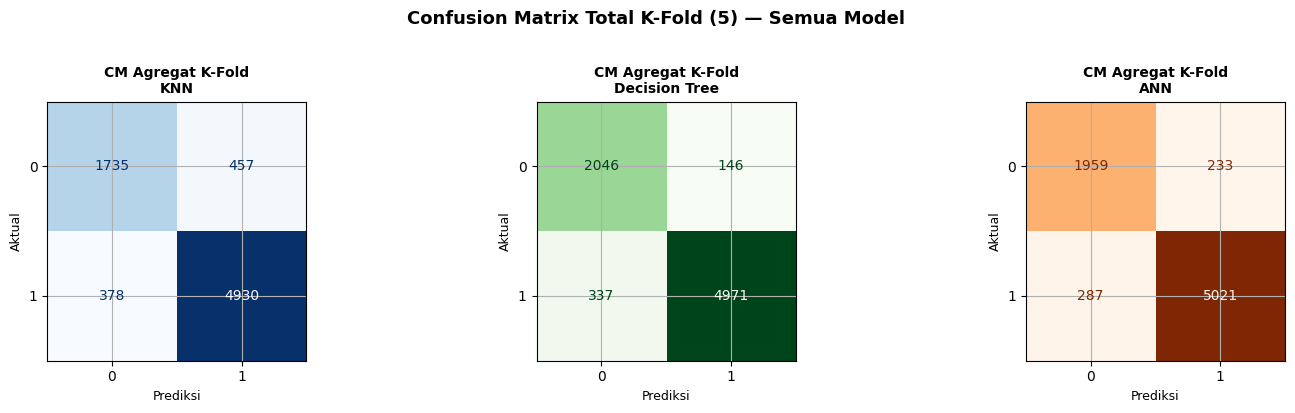

In [ ]:
#  Confusion Matrix Agregat
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cmap_dict = {"KNN":"Blues","Decision Tree":"Greens","ANN":"Oranges"}
data_dict  = {"KNN": knn_kfold_cms, "Decision Tree": dt_kfold_cms, "ANN": ann_kfold_cms}

for ax, (mn, cms) in zip(axes, data_dict.items()):
    cm_total = aggregate_cm(cms)
    plot_cm_single(cm_total, f"CM Agregat K-Fold\n{mn}", ax=ax, cmap=cmap_dict[mn])

fig.suptitle("Confusion Matrix Total K-Fold (5) — Semua Model",
             fontsize=13, fontweight="bold", y=1.02)

plt.tight_layout()
plt.savefig("figures/cm_kfold_agregat_all.png", bbox_inches="tight")
plt.show()

**Evaluasi Data Split Berulang**

In [ ]:
ratios = [0.5, 0.4, 0.3, 0.2, 0.1]
split_frames = []
split_cms = {}

for r in ratios:
    tp_ = int((1-r)*100); te_ = int(r*100)
    split_key = f"{tp_}:{te_}"
    print(f"\n{'='*60}")
    print(f"  Rasio {split_key}  (Train = {int(len(X)*(1-r)):,}  Test = {int(len(X)*r):,})")
    print(f"{'='*60}")

    for name, model in models.items():
        detail_df, cms = evaluate_split_repeated(model, X, y, name, test_size=r, n_repeats=5)
        split_frames.append(detail_df)
        split_cms[(name, split_key)] = cms

        # Tabel
        print(f"\n  {name} | Split {r} ")
        print(f"  {'Trial':>5}  {'RS':>6}  {'Accuracy':>10}  {'Precision':>10}  "
              f"{'Recall':>10}  {'F1-Score':>10}  {'Waktu(s)':>10}")
        print("  " + "-"*72)
        for _, row in detail_df.iterrows():
            print(f"  {int(row['repeat']):>5}  {int(row['random_state']):>6}  "
                  f"{row.accuracy:>10.4f}  {row.precision:>10.4f}  "
                  f"{row.recall:>10.4f}  {row.f1_score:>10.4f}  {row.time_sec:>10.6f}")
        avg = detail_df[["accuracy","precision","recall","f1_score","time_sec"]].mean()
        print("  " + "-"*72)
        print(f"  {'Mean':>5}  {'':>6}  "
              f"{avg.accuracy:>10.4f}  {avg.precision:>10.4f}  "
              f"{avg.recall:>10.4f}  {avg.f1_score:>10.4f}  {avg.time_sec:>10.6f}")

split_details = pd.concat(split_frames, ignore_index=True)
split_details.to_csv("results/split_details.csv", index=False)
display(split_details.head())


  Rasio 50:50  (Train = 3,750  Test = 3,750)

KNN - Split 50:50 | Repeat 1
Accuracy  : 0.8893
Precision : 0.8884
Recall    : 0.8893
F1-score  : 0.8888
Time (s)  : 0.3382

KNN - Split 50:50 | Repeat 2
Accuracy  : 0.8891
Precision : 0.8878
Recall    : 0.8891
F1-score  : 0.8882
Time (s)  : 0.3503

KNN - Split 50:50 | Repeat 3
Accuracy  : 0.8933
Precision : 0.8927
Recall    : 0.8933
F1-score  : 0.8930
Time (s)  : 0.3364

KNN - Split 50:50 | Repeat 4
Accuracy  : 0.8907
Precision : 0.8891
Recall    : 0.8907
F1-score  : 0.8894
Time (s)  : 0.3305

KNN - Split 50:50 | Repeat 5
Accuracy  : 0.8875
Precision : 0.8862
Recall    : 0.8875
F1-score  : 0.8866
Time (s)  : 0.3617

  KNN | Split 0.5 
  Trial      RS    Accuracy   Precision      Recall    F1-Score    Waktu(s)
  ------------------------------------------------------------------------
      1      42      0.8893      0.8884      0.8893      0.8888    0.338176
      2      43      0.8891      0.8878      0.8891      0.8882    0.350301
      

,model,repeat,random_state,train_size,test_size,accuracy,precision,recall,f1_score,time_sec,tn,fp,fn,tp
0,KNN,1,42,0.5,0.5,0.889333,0.888443,0.889333,0.888798,0.338176,871,225,190,2464
1,KNN,2,43,0.5,0.5,0.889067,0.887815,0.889067,0.888224,0.350301,861,235,181,2473
2,KNN,3,44,0.5,0.5,0.893333,0.892673,0.893333,0.892953,0.336395,883,213,187,2467
3,KNN,4,45,0.5,0.5,0.890667,0.889114,0.890667,0.889408,0.330508,851,245,165,2489
4,KNN,5,46,0.5,0.5,0.887467,0.886189,0.887467,0.886612,0.361730,858,238,184,2470


**Ringkasan Hasil Data Split**

In [ ]:
# Menampilkan split details
print("Split Details:")
display(split_details)

Split Details:


,model,repeat,random_state,train_size,test_size,accuracy,precision,recall,f1_score,time_sec,tn,fp,fn,tp
0,KNN,1,42,0.5,0.5,0.889333,0.888443,0.889333,0.888798,0.338176,871,225,190,2464
1,KNN,2,43,0.5,0.5,0.889067,0.887815,0.889067,0.888224,0.350301,861,235,181,2473
2,KNN,3,44,0.5,0.5,0.893333,0.892673,0.893333,0.892953,0.336395,883,213,187,2467
3,KNN,4,45,0.5,0.5,0.890667,0.889114,0.890667,0.889408,0.330508,851,245,165,2489
4,KNN,5,46,0.5,0.5,0.887467,0.886189,0.887467,0.886612,0.361730,858,238,184,2470
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,ANN,1,42,0.9,0.1,0.910667,0.909854,0.910667,0.910105,17.654450,181,38,29,502
71,ANN,2,43,0.9,0.1,0.932000,0.931912,0.932000,0.931954,17.016109,193,26,25,506
72,ANN,3,44,0.9,0.1,0.921333,0.922233,0.921333,0.921691,17.531050,193,26,33,498
73,ANN,4,45,0.9,0.1,0.929333,0.928765,0.929333,0.928889,17.932967,188,31,22,509


In [ ]:
# Split Summary
split_summary = split_details.groupby(["model", "train_size", "test_size"])[["accuracy", "precision", "recall", "f1_score", "time_sec"]].agg(["mean", "std"])
display(split_summary.round(4))
split_summary.round(6).to_csv("results/split_summary.csv")

accuracy         precision          recall  \
                                       mean     std      mean     std    mean   
model         train_size test_size                                              
ANN           0.5        0.5         0.9275  0.0023    0.9276  0.0022  0.9275   
              0.6        0.4         0.9273  0.0017    0.9272  0.0015  0.9273   
              0.7        0.3         0.9281  0.0032    0.9284  0.0035  0.9281   
              0.8        0.2         0.9236  0.0061    0.9234  0.0058  0.9236   
              0.9        0.1         0.9243  0.0086    0.9240  0.0087  0.9243   
Decision Tree 0.5        0.5         0.9312  0.0027    0.9318  0.0020  0.9312   
              0.6        0.4         0.9351  0.0031    0.9359  0.0052  0.9351   
              0.7        0.3         0.9349  0.0048    0.9376  0.0079  0.9349   
              0.8        0.2         0.9315  0.0034    0.9324  0.0034  0.9315   
              0.9        0.1         0.9371  0.0029    0.9383  0.0054  0.9371   
KNN           0.5        0.5         0.8900  0.0022    0.8888  0.0024  0.8900   
              0.6        0.4         0.8888  0.0063    0.8879  0.0062  0.8888   
              0.7        0.3         0.8879  0.0033    0.8867  0.0034  0.8879   
              0.8        0.2         0.8876  0.0040    0.8863  0.0042  0.8876   
              0.9        0.1         0.8920  0.0087    0.8910  0.0084  0.8920   

                                           f1_score         time_sec          
                                       std     mean     std     mean     std  
model         train_size test_size                                            
ANN           0.5        0.5        0.0023   0.9274  0.0023   9.4694  0.7745  
              0.6        0.4        0.0017   0.9272  0.0015  10.4647  2.2751  
              0.7        0.3        0.0032   0.9281  0.0034  11.2228  3.7453  
              0.8        0.2        0.0061   0.9235  0.0059  15.2730  0.0361  
              0.9        0.1        0.0086   0.9240  0.0086  17.4583  0.3727  
Decision Tree 0.5        0.5        0.0027   0.9304  0.0027   0.0682  0.0025  
              0.6        0.4        0.0031   0.9348  0.0038   0.0467  0.0030  
              0.7        0.3        0.0048   0.9351  0.0054   0.0473  0.0025  
              0.8        0.2        0.0034   0.9315  0.0034   0.0687  0.0175  
              0.9        0.1        0.0029   0.9372  0.0034   0.0798  0.0013  
KNN           0.5        0.5        0.0022   0.8892  0.0023   0.3434  0.0125  
              0.6        0.4        0.0063   0.8883  0.0062   0.3707  0.0236  
              0.7        0.3        0.0033   0.8871  0.0034   0.3068  0.0161  
              0.8        0.2        0.0040   0.8866  0.0043   0.3898  0.0230  
              0.9        0.1        0.0087   0.8911  0.0085   0.2519  0.0175

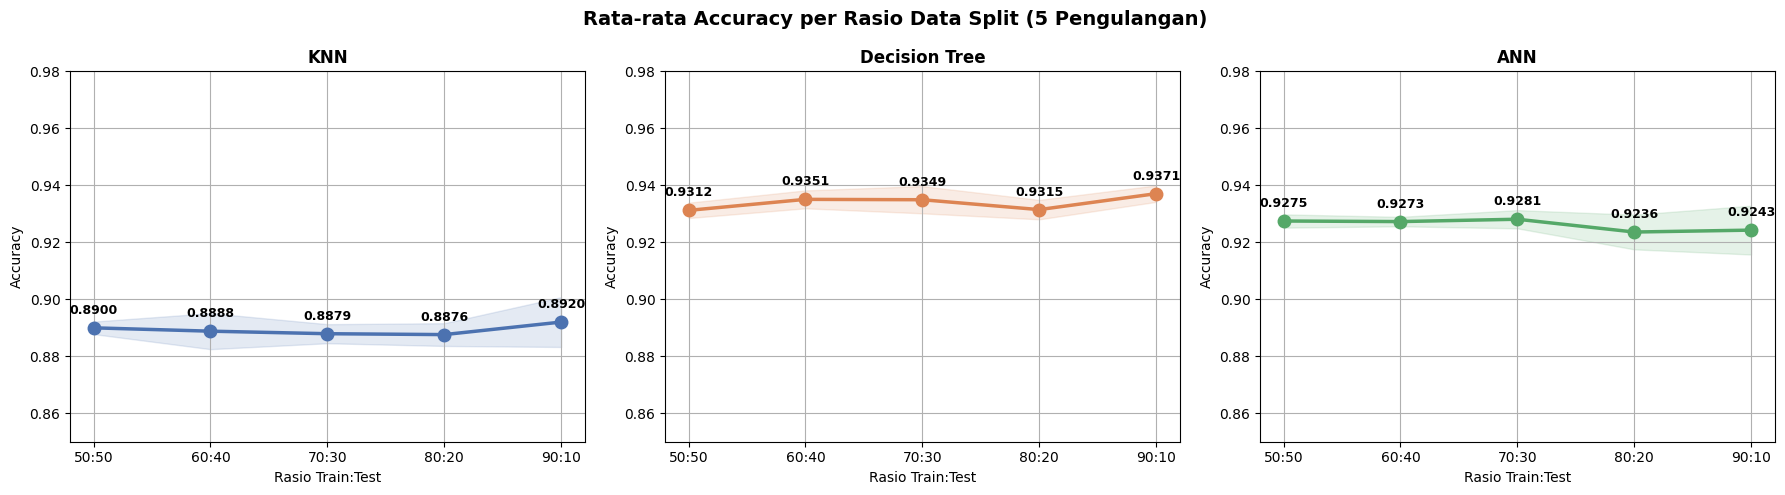

In [ ]:
# Line Chart Akurasi
split_labels = [f"{int((1-r)*100)}:{int(r*100)}" for r in ratios]
split_mean   = split_details.groupby(["model", "train_size", "test_size"])[["accuracy", "precision", "recall", "f1_score", "time_sec"]].mean().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Rata-rata Accuracy per Rasio Data Split (5 Pengulangan)",
             fontsize=14, fontweight="bold")

for ax, name in zip(axes, ["KNN","Decision Tree","ANN"]):
    sub = split_mean[split_mean["model"]==name].copy()
    sub["order"] = sub[["train_size", "test_size"]].apply(
        lambda s: split_labels.index(f"{int(s['train_size']*100)}:{int(s['test_size']*100)}") if f"{int(s['train_size']*100)}:{int(s['test_size']*100)}" in split_labels else 99, axis=1)
    sub = sub.sort_values("order")

    std_vals = (split_details[split_details["model"]==name]
                .groupby(["train_size", "test_size"])["accuracy"].std().reindex([float(sl.split(':')[0])/100 for sl in split_labels], level='train_size').reindex([float(sl.split(':')[1])/100 for sl in split_labels], level='test_size').values)
    acc_vals = sub["accuracy"].values

    ax.plot(split_labels, acc_vals, marker="o", color=MODEL_COLORS[name],
            lw=2.5, markersize=9)
    ax.fill_between(split_labels,
                    acc_vals - std_vals, acc_vals + std_vals,
                    alpha=0.15, color=MODEL_COLORS[name])
    for sl, v in zip(split_labels, acc_vals):
        ax.annotate(f"{v:.4f}", (sl, v),
                    textcoords="offset points", xytext=(0, 10),
                    ha="center", fontsize=9, fontweight="bold")
    ax.set_title(name, fontweight="bold", fontsize=12)
    ax.set_xlabel("Rasio Train:Test", fontsize=10)
    ax.set_ylabel("Accuracy", fontsize=10)
    ax.set_ylim(0.85, 0.98)

plt.tight_layout()
plt.savefig("figures/split_accuracy_chart.png", bbox_inches="tight")
plt.show()

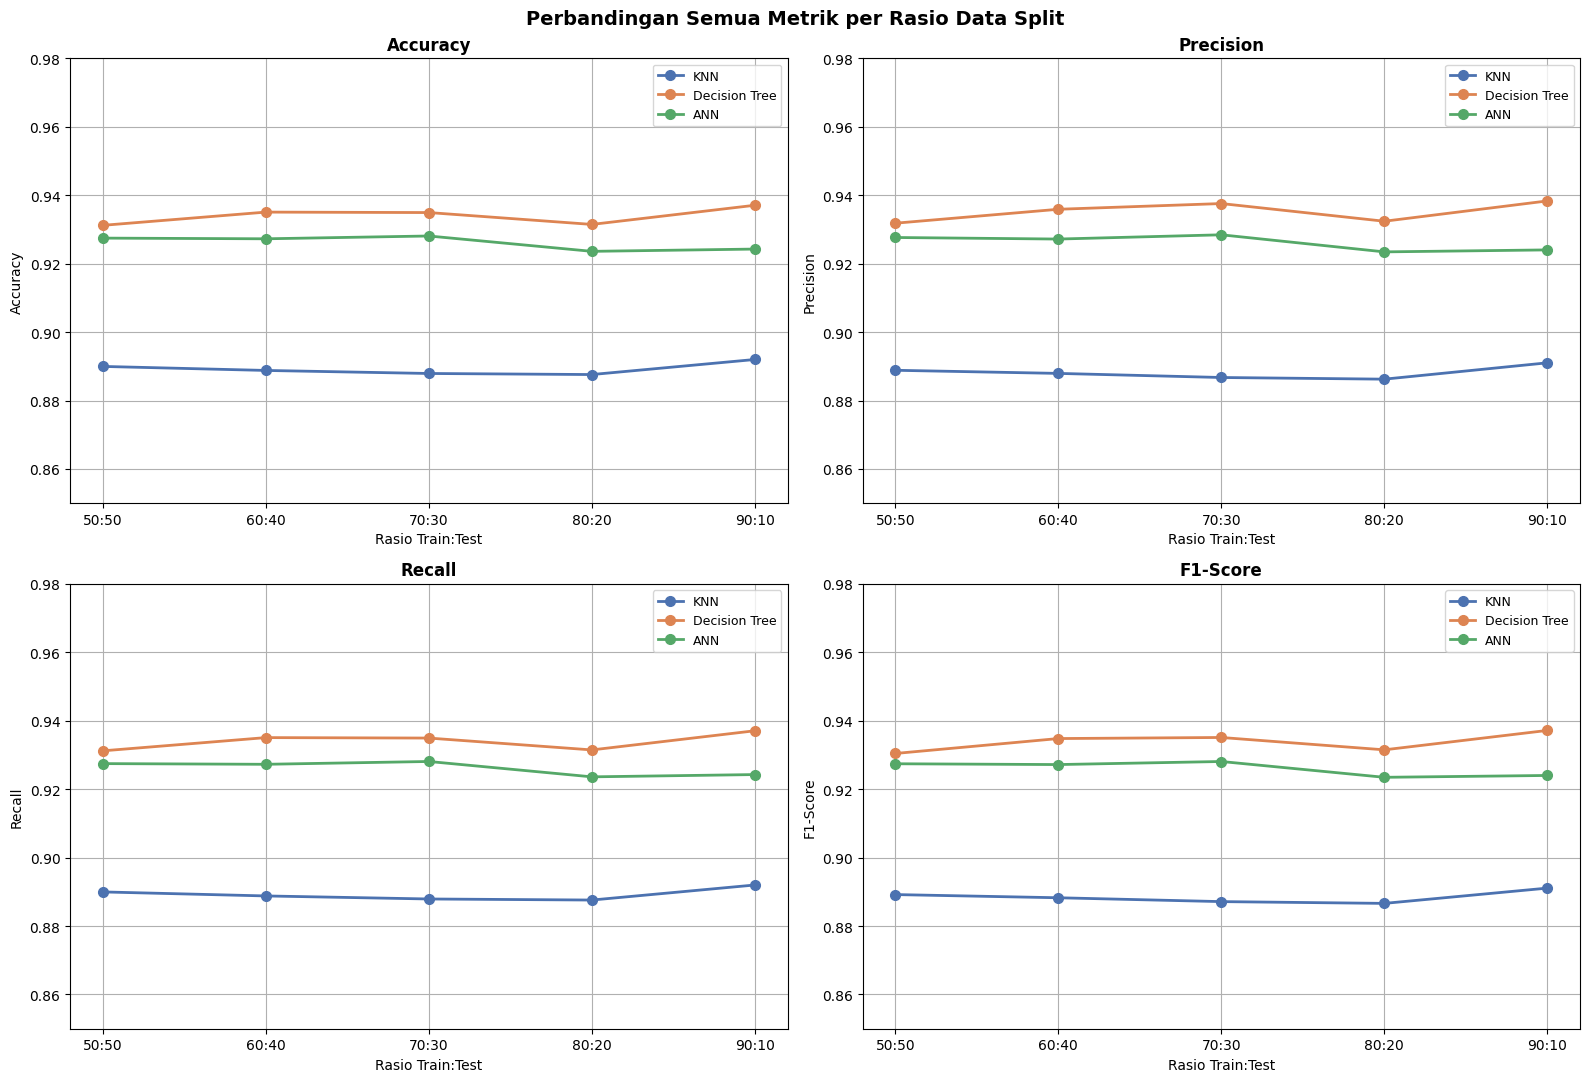

In [ ]:
# Line Chart
metric_pairs = [("accuracy","Accuracy"),("precision","Precision"),
                ("recall","Recall"),("f1_score","F1-Score")]
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Perbandingan Semua Metrik per Rasio Data Split",
             fontsize=14, fontweight="bold")

for ax, (met, label) in zip(axes.flatten(), metric_pairs):
    for name in ["KNN","Decision Tree","ANN"]:
        sub = split_mean[split_mean["model"]==name].copy()
        sub["order"] = sub[["train_size", "test_size"]].apply(
            lambda s: split_labels.index(f"{int(s['train_size']*100)}:{int(s['test_size']*100)}") if f"{int(s['train_size']*100)}:{int(s['test_size']*100)}" in split_labels else 99, axis=1)
        sub = sub.sort_values("order")
        ax.plot(split_labels, sub[met].values, marker="o",
                color=MODEL_COLORS[name], lw=2, markersize=7, label=name)
    ax.set_title(label, fontweight="bold", fontsize=12)
    ax.set_xlabel("Rasio Train:Test", fontsize=10)
    ax.set_ylabel(label, fontsize=10)
    ax.set_ylim(0.85, 0.98)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("figures/split_all_metrics.png", bbox_inches="tight")
plt.show()

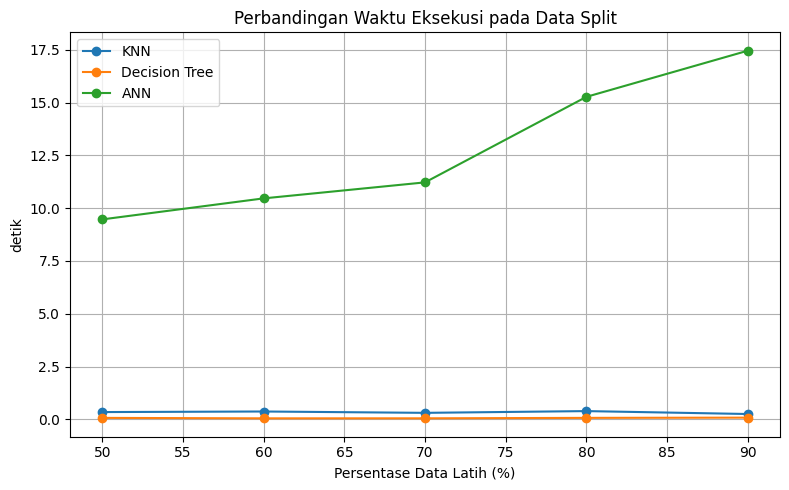

In [ ]:
# Line Chart Perbandingan Waktu
plt.figure()
for model_name in ["KNN", "Decision Tree", "ANN"]:
    temp = split_mean[split_mean["model"] == model_name].sort_values("train_size")
    plt.plot(temp["train_size"] * 100, temp["time_sec"], marker="o", label=model_name)
plt.title("Perbandingan Waktu Eksekusi pada Data Split")
plt.xlabel("Persentase Data Latih (%)")
plt.ylabel("detik")
plt.legend()
plt.tight_layout()
plt.savefig("figures/split_time.png", dpi=300)
plt.show()

**Conf Matrix Keseluruhan**

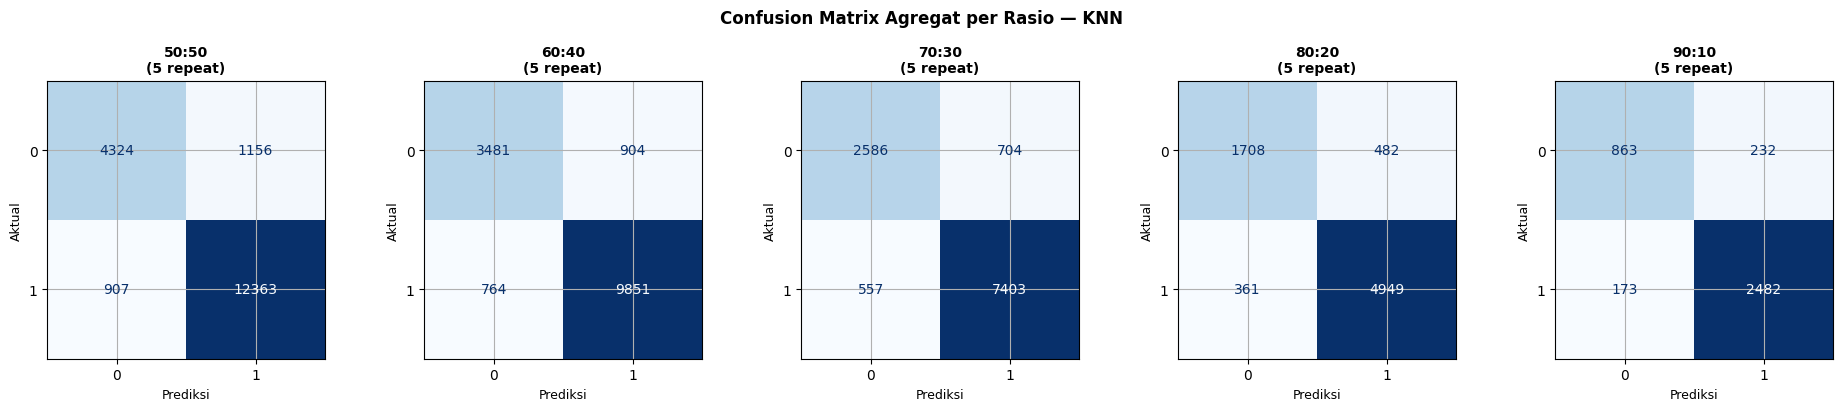

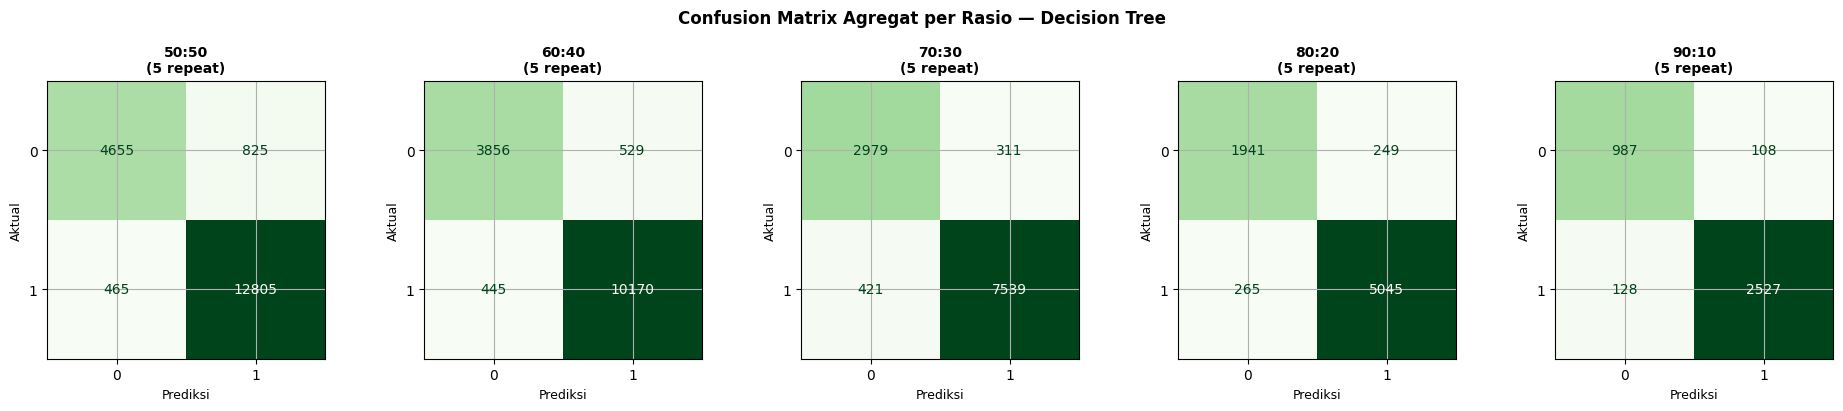

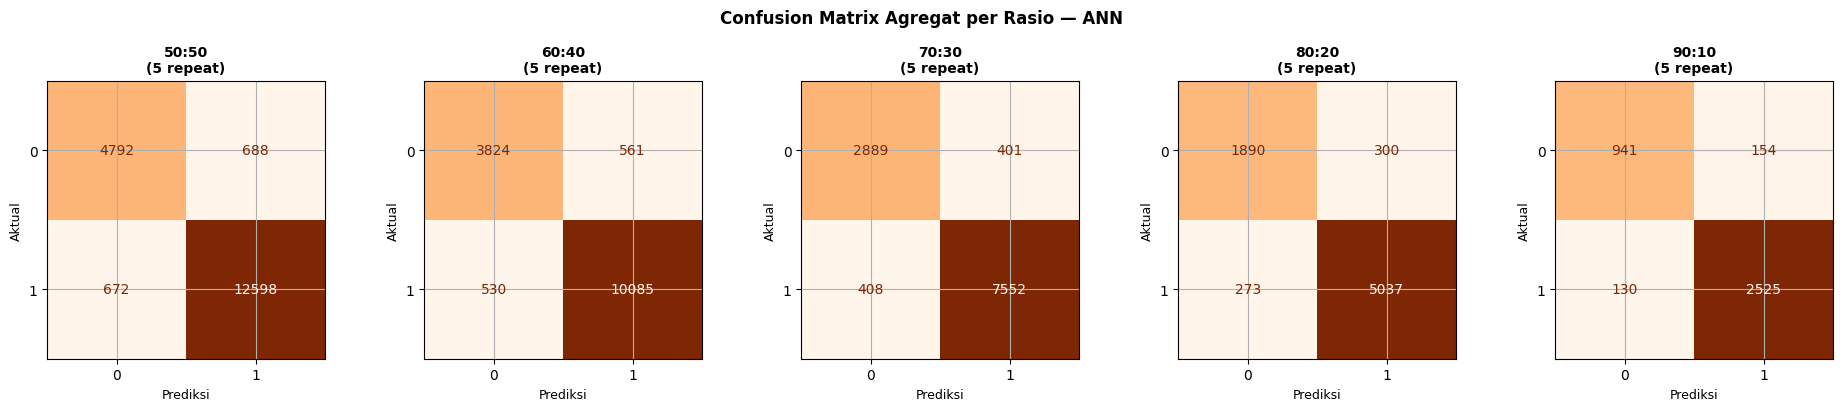

In [ ]:
# Confusion Matrix Agregat per Model per Rasio
for mn in ["KNN","Decision Tree","ANN"]:
    n_ratios = len(ratios)
    fig, axes = plt.subplots(1, n_ratios, figsize=(n_ratios*3.8, 3.8))
    cmap = {"KNN":"Blues","Decision Tree":"Greens","ANN":"Oranges"}[mn]

    for ax, r in zip(axes, ratios):
        split_key = f"{int((1-r)*100)}:{int(r*100)}"
        cm_tot = aggregate_cm(split_cms[(mn, split_key)])
        plot_cm_single(cm_tot, f"{split_key}\n(5 repeat)", ax=ax, cmap=cmap)

    fig.suptitle(f"Confusion Matrix Agregat per Rasio — {mn}",
                 fontweight="bold", y=1.02, fontsize=12)
    plt.tight_layout()
    plt.savefig(f"figures/cm_split_{mn.replace(' ','_').lower()}.png", bbox_inches="tight")
    plt.show()

**Visualisasi Decision Tree**

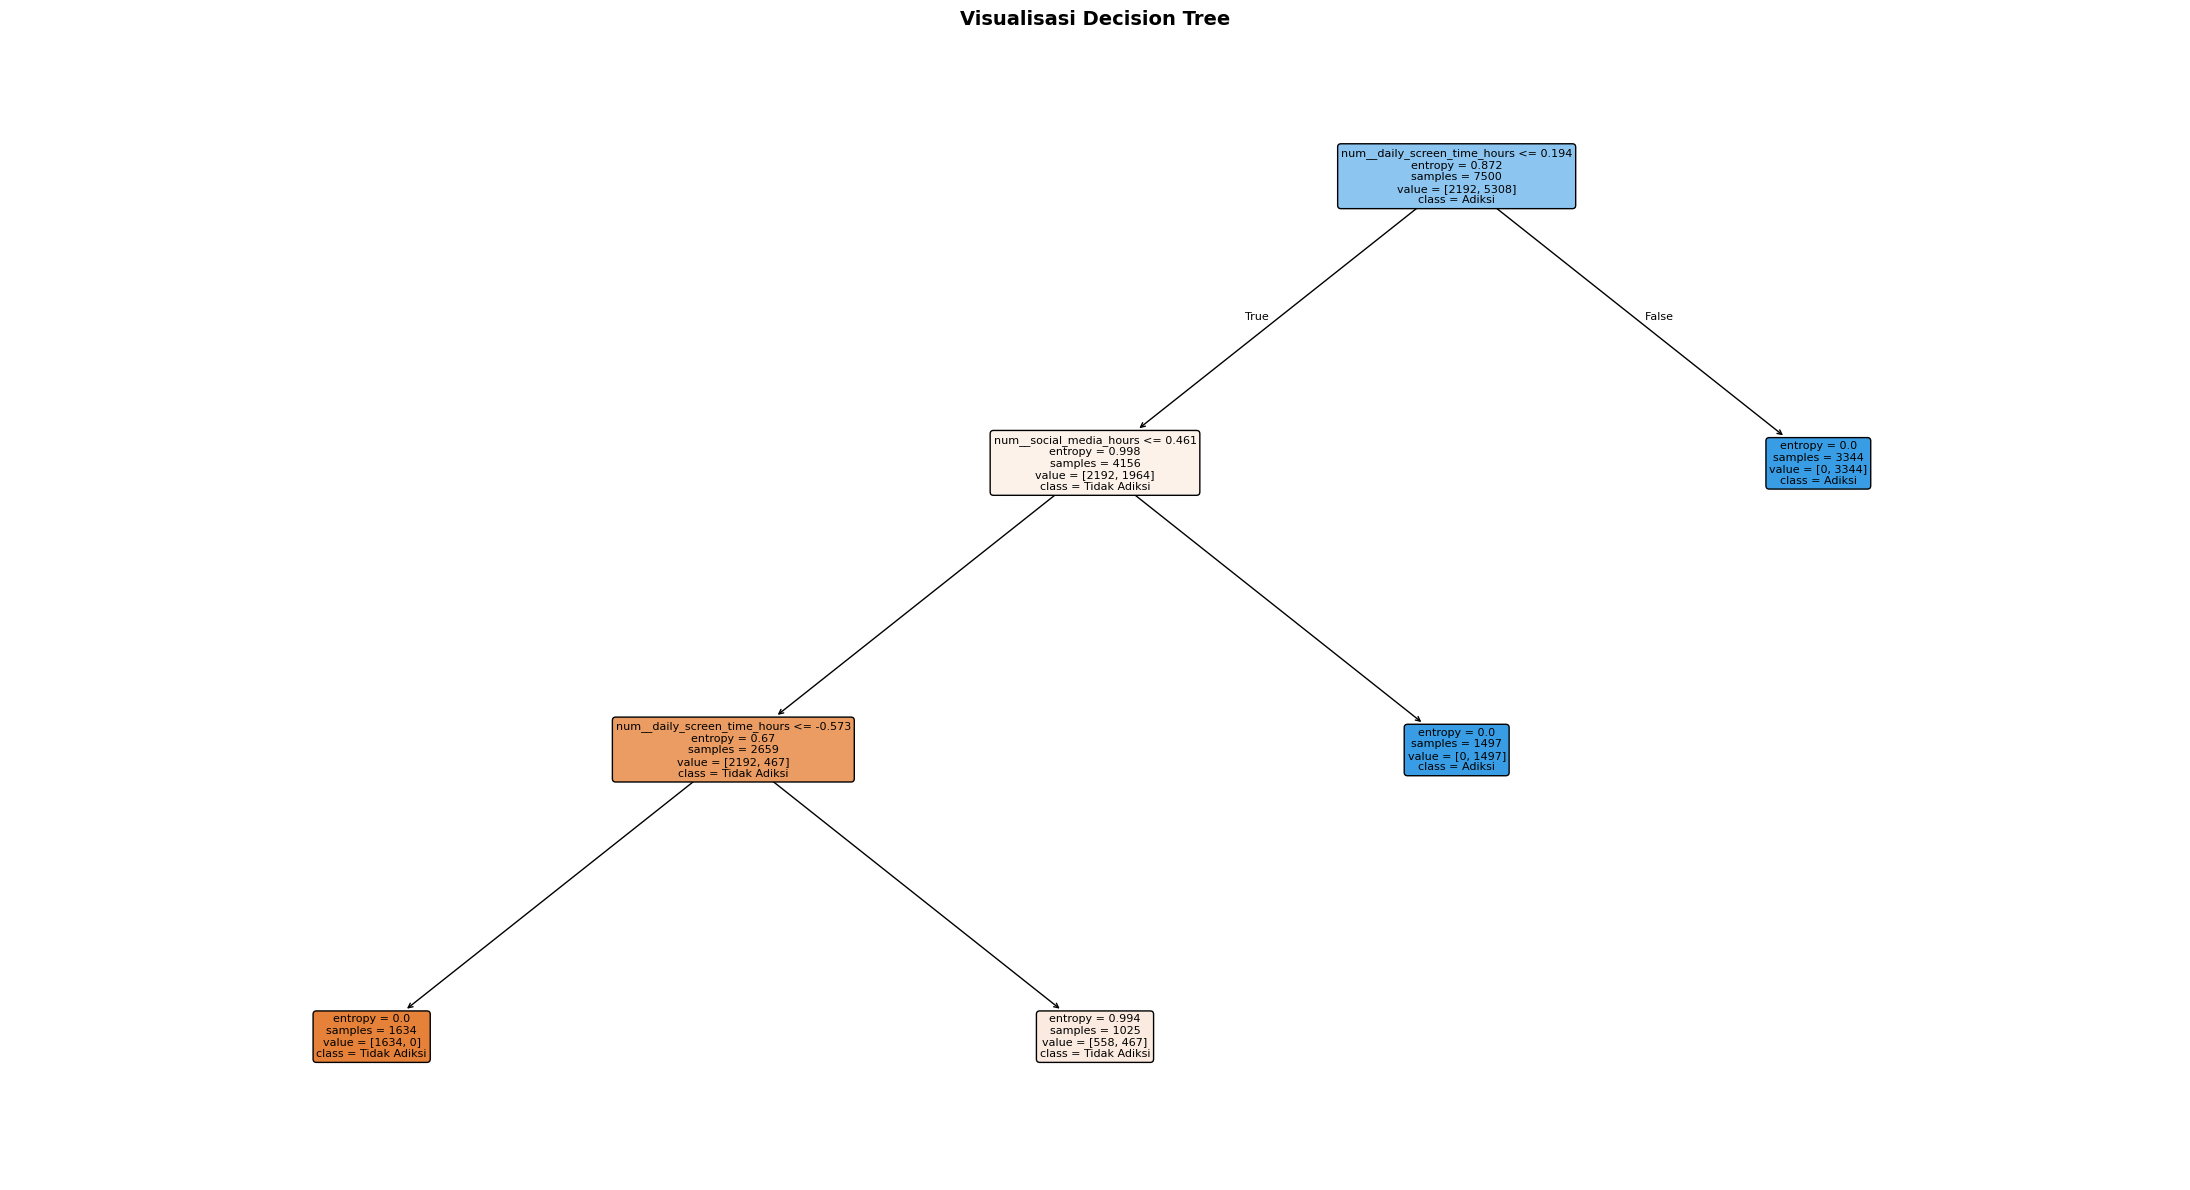

In [ ]:
dt_final = clone(dt_model)

dt_final.named_steps["model"].set_params(max_depth=3)
dt_final.fit(X, y)

feature_names = dt_final.named_steps["preprocessor"].get_feature_names_out()
tree_clf      = dt_final.named_steps["model"]

plt.figure(figsize=(22, 12))
plot_tree(tree_clf, feature_names=feature_names,
          class_names=["Tidak Adiksi","Adiksi"],
          filled=True, rounded=True, max_depth=6, fontsize=8)
plt.title("Visualisasi Decision Tree",
          fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/decision_tree_viz.png", dpi=200, bbox_inches="tight")
plt.show()

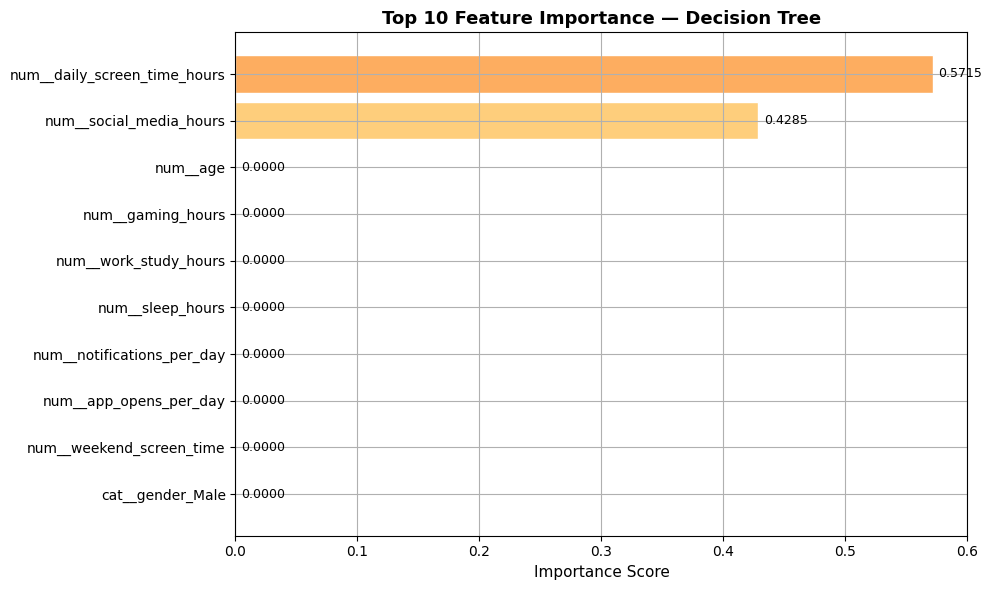


Top 10 Fitur Paling Berpengaruh:
   1. num__daily_screen_time_hours         0.5715  █████████████████████████████████████████████████████████
   2. num__social_media_hours              0.4285  ██████████████████████████████████████████
   3. num__age                             0.0000  
   4. num__gaming_hours                    0.0000  
   5. num__work_study_hours                0.0000  
   6. num__sleep_hours                     0.0000  
   7. num__notifications_per_day           0.0000  
   8. num__app_opens_per_day               0.0000  
   9. num__weekend_screen_time             0.0000  
  10. cat__gender_Male                     0.0000  


In [ ]:
# Feature Importance
fi = pd.Series(tree_clf.feature_importances_, index=feature_names).sort_values(ascending=False)
top10 = fi.head(10)

fig, ax = plt.subplots(figsize=(10, 6))
colors_fi = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(top10)))
ax.barh(top10.index[::-1], top10.values[::-1],
        color=colors_fi[::-1], edgecolor="white")
for i, (idx, val) in enumerate(zip(top10.index[::-1], top10.values[::-1])):
    ax.annotate(f"{val:.4f}", xy=(val, i),
                xytext=(4, 0), textcoords="offset points",
                ha="left", va="center", fontsize=9)
ax.set_title("Top 10 Feature Importance — Decision Tree",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Importance Score", fontsize=11)
plt.tight_layout()
plt.savefig("figures/feature_importance.png", bbox_inches="tight")
plt.show()

print("\nTop 10 Fitur Paling Berpengaruh:")
for i, (f, v) in enumerate(top10.items(), 1):
    bar = "█"*int(v*100)
    print(f"  {i:2}. {f:<35}  {v:.4f}  {bar}")

# **Contoh Simulasi**

In [ ]:
sample = pd.DataFrame([{
    "age": 21, "gender": "Male",
    "daily_screen_time_hours": 7.5, "social_media_hours": 3.0,
    "gaming_hours": 1.5, "work_study_hours": 5.0,
    "sleep_hours": 5.5, "notifications_per_day": 180,
    "app_opens_per_day": 120, "weekend_screen_time": 9.0,
    "stress_level": "High", "academic_work_impact": "Yes"
}])

print("Data Pengguna Baru (Sampel)")
display(sample)
print()

label_map = {0: "Tidak Adiksi (0)", 1: "Adiksi (1)"}
for mn, pipe in models.items():
    m = clone(pipe)
    m.fit(X, y)
    pred  = m.predict(sample)[0]
    proba = m.predict_proba(sample)[0] if hasattr(m, "predict_proba") else None
    print(f"  {mn:<16}: Prediksi → {label_map[pred]}", end="")
    if proba is not None:
        print(f"  | P(Tidak Adiksi)={proba[0]:.4f}  P(Adiksi)={proba[1]:.4f}")
    else:
        print()

Data Pengguna Baru (Sampel)


,age,gender,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,stress_level,academic_work_impact
0,21,Male,7.5,3.0,1.5,5.0,5.5,180,120,9.0,High,Yes



  KNN             : Prediksi → Tidak Adiksi (0)  | P(Tidak Adiksi)=0.6000  P(Adiksi)=0.4000
  Decision Tree   : Prediksi → Tidak Adiksi (0)  | P(Tidak Adiksi)=0.5751  P(Adiksi)=0.4249
  ANN             : Prediksi → Adiksi (1)  | P(Tidak Adiksi)=0.4311  P(Adiksi)=0.5689


**Kesimpulan**

In [ ]:
# Kesimpulan Final
print("Kesimpulan - StratifiedKFold (K=5), average='weighted'")
display(kfold_summary)

best = kfold_summary["accuracy"].idxmax()
fast = kfold_summary["time_sec"].idxmin()
print(f"\n Model dengan Akurasi Terbaik : {best}")
print(f"       Accuracy  : {kfold_summary.loc[best,'accuracy']*100:.2f}%")
print(f"       Precision : {kfold_summary.loc[best,'precision']*100:.2f}%")
print(f"       Recall    : {kfold_summary.loc[best,'recall']*100:.2f}%")
print(f"       F1-Score  : {kfold_summary.loc[best,'f1_score']*100:.2f}%")
print(f"       Waktu     : {kfold_summary.loc[best,'time_sec']:.6f}s")
print(f"\n Model Tercepat      : {fast}")
print(f"       Waktu rata-rata : {kfold_summary.loc[fast,'time_sec']:.6f}s")
print()

print("\nFile yang dihasilkan:")
for f in sorted(os.listdir("figures")): print(f"  figures/{f}")
for f in sorted(os.listdir("results")): print(f"  results/{f}")

Kesimpulan - StratifiedKFold (K=5), average='weighted'


,accuracy,precision,recall,f1_score,time_sec
KNN,0.888667,0.887804,0.888667,0.888065,0.223965
Decision Tree,0.935600,0.941296,0.935600,0.936222,0.052672
ANN,0.930667,0.931335,0.930667,0.930907,15.841105



 Model dengan Akurasi Terbaik : Decision Tree
       Accuracy  : 93.56%
       Precision : 94.13%
       Recall    : 93.56%
       F1-Score  : 93.62%
       Waktu     : 0.052672s

 Model Tercepat      : Decision Tree
       Waktu rata-rata : 0.052672s


File yang dihasilkan:
  figures/categorical_features.png
  figures/cm_fold_ann.png
  figures/cm_fold_decision_tree.png
  figures/cm_fold_knn.png
  figures/cm_kfold_agregat_all.png
  figures/cm_split_ann.png
  figures/cm_split_decision_tree.png
  figures/cm_split_knn.png
  figures/decision_tree_viz.png
  figures/feature_importance.png
  figures/kfold_metrics_comparison.png
  figures/kfold_training_time.png
  figures/numeric_features.png
  figures/split_accuracy_chart.png
  figures/split_all_metrics.png
  figures/split_time.png
  figures/target_distribution.png
  results/kfold_summary.csv
  results/split_details.csv
  results/split_summary.csv


**Classification Report Data Split 80:20**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Data latih : {len(X_train):,} sampel")
print(f"Data uji   : {len(X_test):,} sampel")

for mn, pipe in models.items():
    m = clone(pipe)
    m.fit(X_train, y_train)
    yp = m.predict(X_test)
    acc = accuracy_score(y_test, yp)
    prec = precision_score(y_test, yp, average="weighted",zero_division=0)
    rec = recall_score(y_test, yp, average="weighted",zero_division=0)
    f1 = f1_score(y_test, yp, average="weighted",zero_division=0)
    cm = confusion_matrix(y_test, yp, labels=[0, 1])
    tn = cm[0, 0]
    fp = cm[0, 1]
    fn = cm[1, 0]
    tp= cm[1, 1]
    print(f"  Classification Report — {mn} (Split 80:20)")
    print(classification_report(y_test, yp,
          target_names=["Tidak Adiksi (0)","Adiksi (1)"], digits=4))
    print(f"TN = {tn} FP = {fp} FN = {fn} TP = {tp}")


Data latih : 6,000 sampel
Data uji   : 1,500 sampel
  Classification Report — KNN (Split 80:20)
                  precision    recall  f1-score   support

Tidak Adiksi (0)     0.8275    0.7557    0.7900       438
      Adiksi (1)     0.9027    0.9350    0.9186      1062

        accuracy                         0.8827      1500
       macro avg     0.8651    0.8454    0.8543      1500
    weighted avg     0.8808    0.8827    0.8810      1500

TN = 331 FP = 107 FN = 69 TP = 993
  Classification Report — Decision Tree (Split 80:20)
                  precision    recall  f1-score   support

Tidak Adiksi (0)     0.9111    0.8425    0.8754       438
      Adiksi (1)     0.9370    0.9661    0.9513      1062

        accuracy                         0.9300      1500
       macro avg     0.9240    0.9043    0.9134      1500
    weighted avg     0.9294    0.9300    0.9292      1500

TN = 369 FP = 69 FN = 36 TP = 1026
  Classification Report — ANN (Split 80:20)
                  precision    rec

In [ ]:
split_80_20_details = split_details[split_details['test_size'] == 0.2]

print("Detail Confusion Matrix per Model dan Pengulangan pada Split 80:20:")
for model_name in models.keys():
    print(f"\n {model_name} ")
    display(split_80_20_details[split_80_20_details['model'] == model_name][['repeat', 'accuracy','precision','recall','f1_score','tn', 'fp', 'fn', 'tp']].round(4))

Detail Confusion Matrix per Model dan Pengulangan pada Split 80:20:

 KNN 


,repeat,accuracy,precision,recall,f1_score,tn,fp,fn,tp
45,1,0.8827,0.8808,0.8827,0.8810,331,107,69,993
46,2,0.8887,0.8872,0.8887,0.8876,341,97,70,992
47,3,0.8853,0.8841,0.8853,0.8845,342,96,76,986
48,4,0.8933,0.8922,0.8933,0.8926,348,90,70,992
49,5,0.8880,0.8870,0.8880,0.8874,346,92,76,986



 Decision Tree 


,repeat,accuracy,precision,recall,f1_score,tn,fp,fn,tp
50,1,0.9300,0.9294,0.9300,0.9292,369,69,36,1026
51,2,0.9340,0.9340,0.9340,0.9340,388,50,49,1013
52,3,0.9267,0.9302,0.9267,0.9276,404,34,76,986
53,4,0.9353,0.9377,0.9353,0.9360,406,32,65,997
54,5,0.9313,0.9307,0.9313,0.9307,374,64,39,1023



 ANN 


,repeat,accuracy,precision,recall,f1_score,tn,fp,fn,tp
55,1,0.9273,0.9276,0.9273,0.9275,386,52,57,1005
56,2,0.9273,0.9268,0.9273,0.9269,375,63,46,1016
57,3,0.9133,0.9137,0.9133,0.9135,376,62,68,994
58,4,0.9273,0.9268,0.9273,0.9270,377,61,48,1014
59,5,0.9227,0.9223,0.9227,0.9225,376,62,54,1008
